# Lab Assignment 7 — Hindi POS Tagger
Naive Bayes and HMM (forward, backward, forward-backward Viterbi). Probabilities come from the train split; evaluated on dev and test with per-tag F1.

**Setup:** put the `Hindi-POS-Data` folder (with `hindi-train-pos.txt`, `hindi-dev-pos.txt`, `hindi-test-pos.txt`) next to this notebook, or change `DATA_DIR` below. In Colab, upload the folder first.

In [1]:
import os
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

%matplotlib inline
START, END, UNK = "<S>", "</S>", "<UNK>"

## 1. Load data

In [2]:
def read_pos_file(path):
    """Return list of sentences; each sentence = (words, tags). Blank line = sentence break."""
    sents, words, tags = [], [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if words:
                    sents.append((words, tags))
                    words, tags = [], []
                continue
            parts = line.split()
            words.append(parts[0])
            tags.append(parts[-1])
    if words:
        sents.append((words, tags))
    return sents

In [3]:
DATA_DIR = "Hindi-POS-Data"   # <-- change if your folder is elsewhere
OUT_DIR = "results"
os.makedirs(os.path.join(OUT_DIR, "charts"), exist_ok=True)

train = read_pos_file(os.path.join(DATA_DIR, "hindi-train-pos.txt"))
splits = {
    "dev": read_pos_file(os.path.join(DATA_DIR, "hindi-dev-pos.txt")),
    "test": read_pos_file(os.path.join(DATA_DIR, "hindi-test-pos.txt")),
}
print(f"train sents={len(train)}  dev={len(splits['dev'])}  test={len(splits['test'])}")
print(train[0])

train sents=15087  dev=1866  test=1910
(['यह', 'एशिया', 'की', 'सबसे', 'बड़ी', 'मस्जिदों', 'में', 'से', 'एक', 'है', '।'], ['DM_DMD', 'N_NNP', 'PSP', 'RP_INTF', 'JJ', 'N_NN', 'PSP', 'PSP', 'QT_QTC', 'V_VM', 'RD_PUNC'])


## 2. Naive Bayes
Features: length (MORE if > 4 chars else LESS), word, previous word, next word, previous tag. Add-α smoothing; at test time the previous tag is the *predicted* previous tag.

In [4]:
class NaiveBayesTagger:
    """
    P(tag | feats) ~ P(tag) * P(len|tag) * P(word|tag) * P(prev_word|tag)
                              * P(next_word|tag) * P(prev_tag|tag)
    Add-alpha smoothing; unseen feature values get alpha / (N_tag + alpha*(V+1)).
    At test time the previous tag is the tag *predicted* for the previous word.
    """
    FEATS = ["len", "word", "prev_word", "next_word", "prev_tag"]

    def __init__(self, alpha=0.1):
        self.alpha = alpha

    @staticmethod
    def _feats(words, i, prev_tag):
        w = words[i]
        return {
            "len": "MORE" if len(w) > 4 else "LESS",
            "word": w,
            "prev_word": words[i - 1] if i > 0 else START,
            "next_word": words[i + 1] if i < len(words) - 1 else END,
            "prev_tag": prev_tag,
        }

    def fit(self, sents):
        self.tags = sorted({t for _, ts in sents for t in ts})
        self.tag_idx = {t: i for i, t in enumerate(self.tags)}
        T = len(self.tags)
        self.tag_count = np.zeros(T)
        cnt = {f: defaultdict(lambda: np.zeros(T)) for f in self.FEATS}
        for words, tags in sents:
            prev = START
            for i, t in enumerate(tags):
                ti = self.tag_idx[t]
                self.tag_count[ti] += 1
                for f, v in self._feats(words, i, prev).items():
                    cnt[f][v][ti] += 1
                prev = t
        self.log_prior = np.log(self.tag_count / self.tag_count.sum())
        self.vocab = {}
        self.logp = {}
        self.logunk = {}
        for f in self.FEATS:
            vals = list(cnt[f].keys())
            V = len(vals)
            self.vocab[f] = {v: j for j, v in enumerate(vals)}
            M = np.stack([cnt[f][v] for v in vals])  # V x T
            denom = self.tag_count + self.alpha * (V + 1)
            self.logp[f] = np.log((M + self.alpha) / denom)
            self.logunk[f] = np.log(self.alpha / denom)
        return self

    def _score(self, feats):
        s = self.log_prior.copy()
        for f, v in feats.items():
            j = self.vocab[f].get(v)
            s += self.logp[f][j] if j is not None else self.logunk[f]
        return s

    def predict_sentence(self, words):
        out, prev = [], START
        for i in range(len(words)):
            t = self.tags[int(np.argmax(self._score(self._feats(words, i, prev))))]
            out.append(t)
            prev = t
        return out

## 3. HMM
Bigram HMM with transition and emission probabilities from train (add-α smoothing, unseen words get a small uniform-by-tag emission).
- **Forward Viterbi:** left-to-right, P(tag | previous tag)
- **Backward Viterbi:** right-to-left, P(tag | next tag)
- **Forward-backward Viterbi:** per position, tag = argmax of (best forward path score + best backward path score)

In [5]:
class HMMTagger:
    """
    Bigram HMM. Parameters estimated from the training data (add-alpha smoothed):
      A[p, c]  = P(tag_c | tag_p)    with start row (<S>) and an end column handled separately
      A_end[p] = P(</S> | tag_p)
      B[c, w]  = P(word | tag_c)     unknown words -> alpha/(N_tag + alpha*(V+1))
    Backward model (for backward Viterbi) is the right-to-left factorisation:
      Ab[n, c] = P(tag_c | next tag_n), Ab_start[c] = P(tag_c | </S>)
    """

    def __init__(self, alpha_trans=0.01, alpha_emit=0.01):
        self.at, self.ae = alpha_trans, alpha_emit

    def fit(self, sents):
        self.tags = sorted({t for _, ts in sents for t in ts})
        self.tag_idx = {t: i for i, t in enumerate(self.tags)}
        T = len(self.tags)
        self.T = T
        trans = np.zeros((T + 1, T + 1))  # rows: prev (T=START), cols: cur (T=END)
        emit = defaultdict(lambda: np.zeros(T))
        tag_count = np.zeros(T)
        for words, tags in sents:
            ids = [self.tag_idx[t] for t in tags]
            seq = [T] + ids + [T]
            for a, b in zip(seq[:-1], seq[1:]):
                trans[a, b] += 1
            for w, ti in zip(words, ids):
                emit[w][ti] += 1
                tag_count[ti] += 1
        self.words = {w: j for j, w in enumerate(emit)}
        E = np.stack([emit[w] for w in self.words])  # V x T
        V = E.shape[0]
        denom = tag_count + self.ae * (V + 1)
        self.logB = np.log((E + self.ae) / denom).T          # T x V
        self.logB_unk = np.log(self.ae / denom)               # T

        # forward transitions  P(cur | prev)
        f = trans + self.at
        f[:, T] = trans[:, T] + self.at   # ending column
        f[T, T] = 0.0                      # START->END only for empty sents; ignore
        f[:, T] = trans[:, T] + self.at
        f[T, T] = 1e-12
        f = f / f.sum(axis=1, keepdims=True)
        self.logA = np.log(f[:T, :T])
        self.logA_start = np.log(f[T, :T])
        self.logA_end = np.log(f[:T, T])

        # backward transitions P(cur | next)  (next = END is row T; columns cur, START col = T)
        bt = trans.T + self.at                # rows: next(or END at T), cols: cur(or START at T)
        bt[T, :] = trans[:, T] + self.at      # END row: P(cur | END) from cur->END counts
        bt[:, T] = trans[T, :] + self.at      # START column: cur=START
        bt[T, T] = 1e-12
        # bt[n, c] = count(c -> n); the row for "next = n" normalises over c (incl. START)
        bt = bt / bt.sum(axis=1, keepdims=True)
        self.logAb = np.log(bt[:T, :T])         # [next, cur]
        self.logAb_start = np.log(bt[:T, T])    # P(START | next) – final step of reversed chain
        self.logAb_end = np.log(bt[T, :T])      # P(cur | END)
        return self

    def _emit_matrix(self, words):
        cols = []
        for w in words:
            j = self.words.get(w)
            cols.append(self.logB[:, j] if j is not None else self.logB_unk)
        return np.stack(cols)  # n x T

    # --- (a) standard forward Viterbi ---------------------------------------
    def forward_viterbi(self, words, return_scores=False):
        em = self._emit_matrix(words)
        n, T = em.shape
        delta = np.empty((n, T))
        back = np.zeros((n, T), dtype=int)
        delta[0] = self.logA_start + em[0]
        for i in range(1, n):
            cand = delta[i - 1][:, None] + self.logA          # prev x cur
            back[i] = cand.argmax(axis=0)
            delta[i] = cand.max(axis=0) + em[i]
        last = delta[-1] + self.logA_end
        if return_scores:
            return delta, em
        path = [int(last.argmax())]
        for i in range(n - 1, 0, -1):
            path.append(int(back[i][path[-1]]))
        return [self.tags[k] for k in reversed(path)]

    # --- (b) backward Viterbi (right-to-left chain) -------------------------
    def backward_viterbi(self, words):
        em = self._emit_matrix(words)
        n, T = em.shape
        delta = np.empty((n, T))
        back = np.zeros((n, T), dtype=int)
        delta[n - 1] = self.logAb_end + em[n - 1]
        for i in range(n - 2, -1, -1):
            cand = delta[i + 1][:, None] + self.logAb         # next x cur
            back[i] = cand.argmax(axis=0)
            delta[i] = cand.max(axis=0) + em[i]
        first = delta[0] + self.logAb_start
        path = [int(first.argmax())]
        for i in range(0, n - 1):
            path.append(int(back[i][path[-1]]))
        return [self.tags[k] for k in path]

    # --- (c) forward-backward Viterbi ---------------------------------------
    def forward_backward_viterbi(self, words):
        """
        alpha_i(t): best-path score of words[0..i] ending in tag t  (forward Viterbi)
        beta_i(t) : best-path score of words[i+1..n-1] (+ end) given tag t at i (backward Viterbi)
        Tag at each position = argmax_t alpha_i(t) + beta_i(t)  (max-marginal decoding).
        """
        alpha, em = self.forward_viterbi(words, return_scores=True)
        n, T = em.shape
        beta = np.empty((n, T))
        beta[n - 1] = self.logA_end
        for i in range(n - 2, -1, -1):
            beta[i] = (self.logA + (em[i + 1] + beta[i + 1])[None, :]).max(axis=1)
        return [self.tags[int(k)] for k in (alpha + beta).argmax(axis=1)]

## 4. Evaluation helpers and plots

In [6]:
def evaluate(gold, pred, labels):
    p, r, f, s = precision_recall_fscore_support(gold, pred, labels=labels, zero_division=0)
    per_tag = pd.DataFrame({"tag": labels, "precision": p, "recall": r, "f1": f, "support": s})
    summary = {
        "accuracy": accuracy_score(gold, pred),
        "macro_f1": f.mean(),
        "weighted_f1": np.average(f, weights=s),
    }
    return per_tag, summary


def run_model(name, fn, sents):
    gold, pred = [], []
    for words, tags in sents:
        gold.extend(tags)
        pred.extend(fn(words))
    return gold, pred


def plot_per_tag(df, split, out_dir, models):
    tags = df["tag"].unique().tolist()
    # order tags by training frequency is passed via df order; keep as is
    x = np.arange(len(tags))
    w = 0.8 / len(models)
    fig, ax = plt.subplots(figsize=(15, 6))
    for k, m in enumerate(models):
        vals = [df[(df.model == m) & (df.tag == t) & (df.split == split)].f1.values[0] for t in tags]
        ax.bar(x + (k - (len(models) - 1) / 2) * w, vals, w, label=m)
    ax.set_xticks(x)
    ax.set_xticklabels(tags, rotation=60, ha="right")
    ax.set_ylabel("F1-score")
    ax.set_ylim(0, 1.2)
    ax.set_title(f"Per-tag F1 on {split} set (tags ordered by training frequency)")
    ax.legend(ncol=len(models))
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, f"f1_per_tag_{split}.png"), dpi=150)
    plt.show()


def plot_overall(summary_df, out_dir):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, split in zip(axes, ["dev", "test"]):
        d = summary_df[summary_df.split == split].set_index("model")
        d[["accuracy", "macro_f1", "weighted_f1"]].plot.bar(ax=ax, rot=20)
        ax.set_title(f"Overall performance ({split})")
        ax.set_ylim(0, 1.0)
        ax.grid(axis="y", alpha=0.3)
        ax.set_xlabel("")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "overall_comparison.png"), dpi=150)
    plt.show()

## 5. Train and evaluate all models

In [7]:
nb_model = NaiveBayesTagger().fit(train)
hmm_model = HMMTagger().fit(train)
models = {
    "Naive Bayes": nb_model.predict_sentence,
    "HMM forward Viterbi": hmm_model.forward_viterbi,
    "HMM backward Viterbi": hmm_model.backward_viterbi,
    "HMM forward-backward Viterbi": hmm_model.forward_backward_viterbi,
}
freq = Counter(t for _, ts in train for t in ts)
labels = [t for t, _ in freq.most_common()]   # tags ordered by training frequency

rows, summ = [], []
for split, sents in splits.items():
    for name, fn in models.items():
        gold, pred = run_model(name, fn, sents)
        pt, s = evaluate(gold, pred, labels)
        pt.insert(0, "split", split); pt.insert(0, "model", name)
        rows.append(pt); summ.append({"model": name, "split": split, **s})
        print(f"{split:5s} {name:30s} acc={s['accuracy']:.4f}  macroF1={s['macro_f1']:.4f}")
per_tag = pd.concat(rows, ignore_index=True)
summary = pd.DataFrame(summ)
per_tag.to_csv(os.path.join(OUT_DIR, "per_tag_scores.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)

dev   Naive Bayes                    acc=0.9247  macroF1=0.8331


dev   HMM forward Viterbi            acc=0.9299  macroF1=0.8275


dev   HMM backward Viterbi           acc=0.9299  macroF1=0.8275


dev   HMM forward-backward Viterbi   acc=0.9299  macroF1=0.8276


test  Naive Bayes                    acc=0.9257  macroF1=0.8444


test  HMM forward Viterbi            acc=0.9292  macroF1=0.8328


test  HMM backward Viterbi           acc=0.9292  macroF1=0.8328


test  HMM forward-backward Viterbi   acc=0.9292  macroF1=0.8328


### Reading the evaluation log

Each printed row reports token-level accuracy and macro-averaged F1 for one model on one split. Accuracy is the fraction of all tokens assigned the correct POS tag. Macro-F1 computes F1 separately for each tag and then gives every tag equal weight, so it reflects performance on infrequent tags as well as common ones. The dev set is used for comparison during development; the test set is the final held-out evaluation. The scores are close across models: the HMM variants have slightly higher accuracy, while Naive Bayes has higher macro-F1, especially on test. This means the HMM gets a few more tokens right overall, while Naive Bayes has a better average across tags.


## 6. Overall comparison

In [8]:
summary.round(4)

,model,split,accuracy,macro_f1,weighted_f1
0,Naive Bayes,dev,0.9247,0.8331,0.9249
1,HMM forward Viterbi,dev,0.9299,0.8275,0.9309
2,HMM backward Viterbi,dev,0.9299,0.8275,0.9309
3,HMM forward-backward Viterbi,dev,0.9299,0.8276,0.9309
4,Naive Bayes,test,0.9257,0.8444,0.9259
5,HMM forward Viterbi,test,0.9292,0.8328,0.9303
6,HMM backward Viterbi,test,0.9292,0.8328,0.9303
7,HMM forward-backward Viterbi,test,0.9292,0.8328,0.9303


### Interpreting the summary table

The table contains one row per model and split. `weighted_f1` weights each tag's F1 by its number of gold examples, so common tags dominate it; it therefore tends to track accuracy. `macro_f1` weights tags equally and can be lower when rare or ambiguous tags are difficult. On both dev and test, the HMM family leads in accuracy and weighted F1, whereas Naive Bayes leads in macro-F1. The three HMM decoding variants have nearly identical aggregate scores, so the choice of decoding direction makes little difference on these splits.


## 7. F1-score per tag

In [9]:
for split in splits:
    wide = per_tag[per_tag.split == split].pivot(index="tag", columns="model", values="f1").loc[labels]
    print(f"F1 per tag ({split})")
    display(wide.round(3))

F1 per tag (dev)


model,HMM backward Viterbi,HMM forward Viterbi,HMM forward-backward Viterbi,Naive Bayes
tag,,,,
N_NN,0.917,0.917,0.917,0.907
PSP,0.988,0.988,0.988,0.985
N_NNP,0.831,0.831,0.831,0.836
V_VM,0.954,0.954,0.954,0.959
V_VAUX,0.964,0.964,0.964,0.974
RD_PUNC,1.000,1.000,1.000,0.993
JJ,0.889,0.889,0.889,0.869
PR_PRP,0.962,0.962,0.962,0.897
QT_QTC,0.896,0.896,0.896,0.917


F1 per tag (test)


model,HMM backward Viterbi,HMM forward Viterbi,HMM forward-backward Viterbi,Naive Bayes
tag,,,,
N_NN,0.911,0.911,0.911,0.901
PSP,0.986,0.986,0.986,0.982
N_NNP,0.840,0.840,0.840,0.841
V_VM,0.953,0.953,0.953,0.963
V_VAUX,0.967,0.967,0.967,0.976
RD_PUNC,1.000,1.000,1.000,0.994
JJ,0.905,0.905,0.905,0.887
PR_PRP,0.963,0.963,0.963,0.907
QT_QTC,0.871,0.871,0.871,0.920


### Interpreting the per-tag tables

Each cell is that model's F1 for the tag in that row, rounded to three decimals. F1 combines precision (how often predictions of that tag are correct) and recall (how many gold instances of the tag are found). Tags are listed in descending training frequency, making it easier to compare common tags near the top with less frequent tags farther down. Compare models across a row to see which method handles that tag better; low scores indicate that the tag is harder to identify, while a score of 1.000 indicates perfect precision and recall on that split.


## 8. Charts

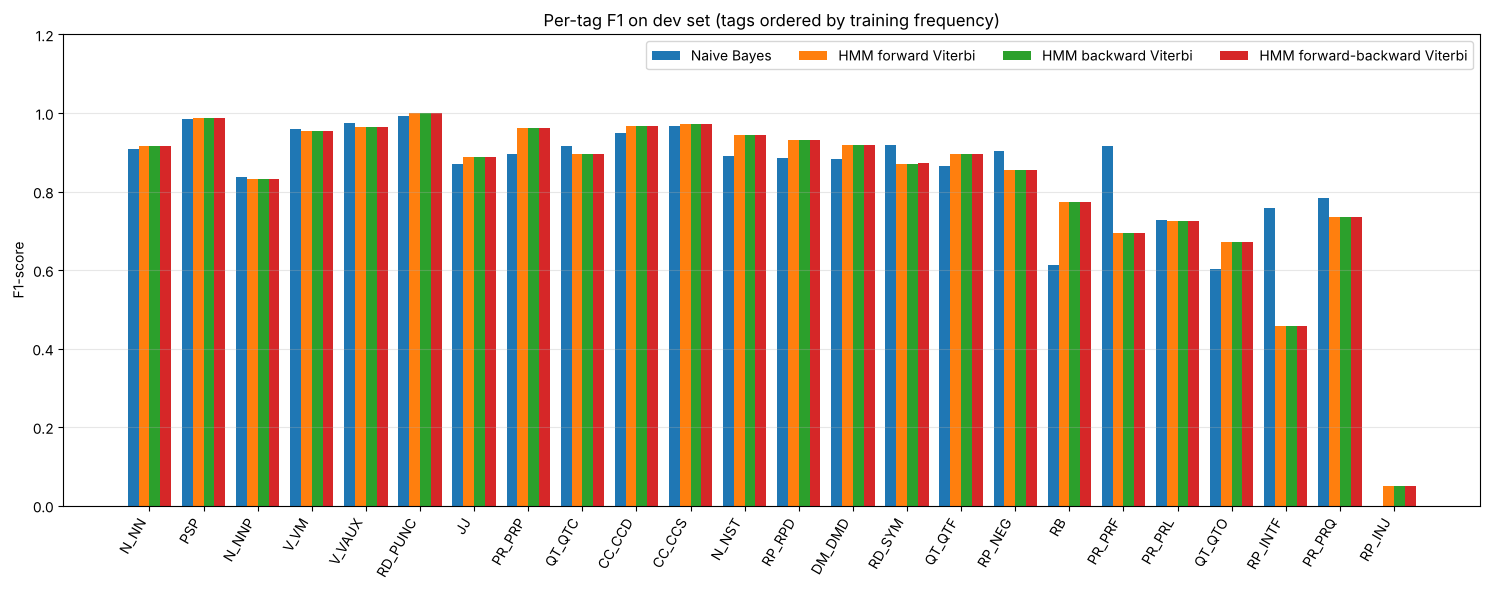

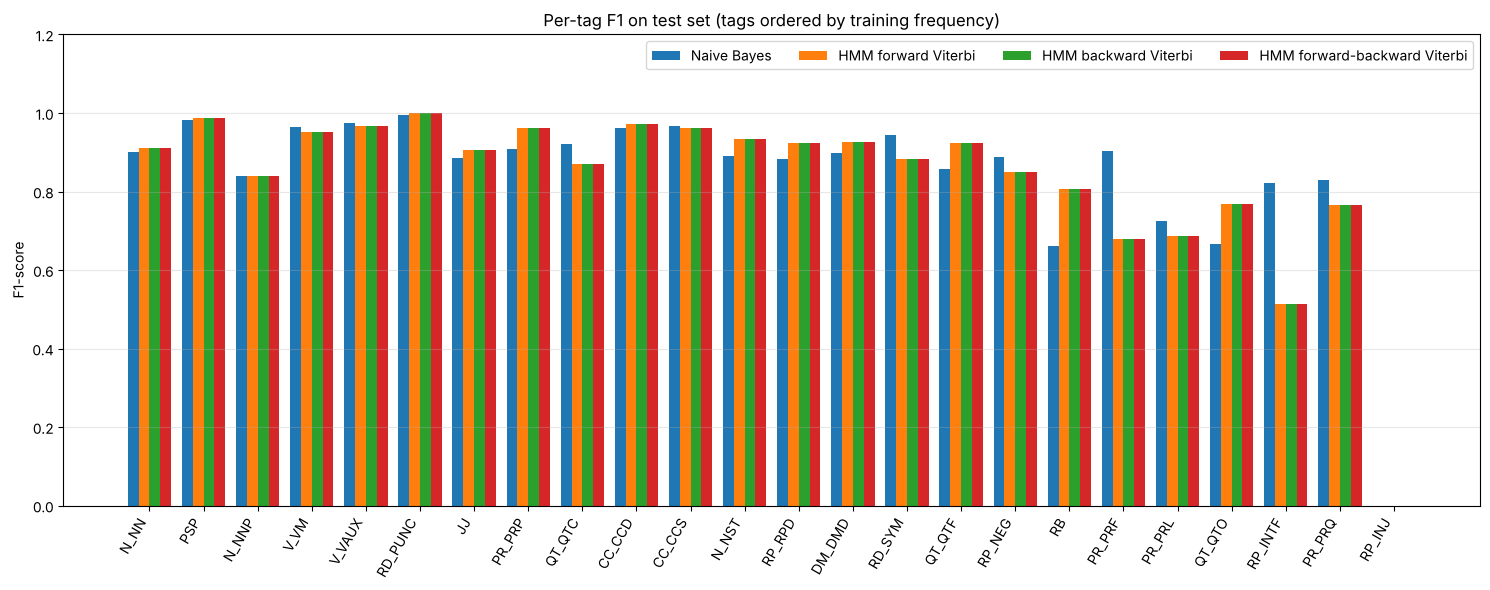

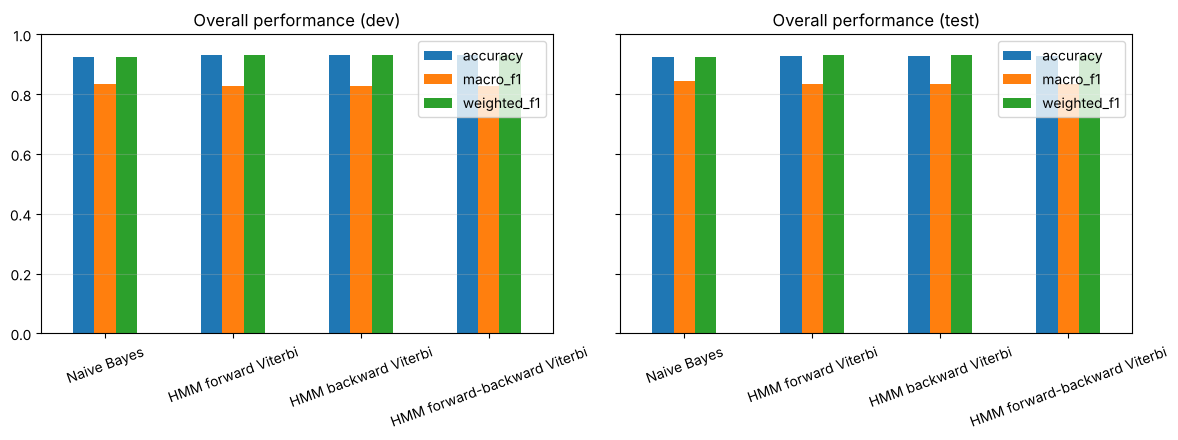

In [10]:
for split in splits:
    plot_per_tag(per_tag, split, os.path.join(OUT_DIR, "charts"), list(models))
plot_overall(summary, os.path.join(OUT_DIR, "charts"))

### How to read the graphs

The dev and test per-tag charts show grouped bars: each group is a POS tag and each color is a model. Taller bars mean higher F1; the y-axis is capped at 1, with extra headroom for the legend/layout. Tags follow training-frequency order. These charts expose differences that an overall average can hide, especially for less common tags. The overall comparison has separate panels for dev and test and groups accuracy, macro-F1, and weighted F1 for every model. Accuracy and weighted F1 are generally higher because frequent tags contribute more; macro-F1 can differ because each tag counts equally. Across the charts, the HMM bars are similar to each other, while the Naive Bayes model trades a small amount of overall accuracy for stronger macro-F1.


## 9. Observations
- HMM decoding has slightly higher accuracy than Naive Bayes on both splits: about 93.0% versus 92.5% on dev, and 92.9% versus 92.6% on test.
- Naive Bayes has higher macro-F1 on both splits (0.8331 vs about 0.8275 on dev; 0.8444 vs about 0.8328 on test). Because macro-F1 weights tags equally, this suggests a stronger average across tag categories even though fewer total tokens are correct.
- The forward, backward, and forward-backward HMM variants produce nearly identical aggregate results in this run. Per-tag tables and charts are useful for spotting where any smaller differences occur.
- Scores for rare tags should be interpreted cautiously: a small number of training examples gives the model little evidence to learn reliable patterns, and a few errors can substantially change that tag?s F1.
